# single simulation of the circuit model for swimming under normoxia conditions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.random import RandomState
import pandas as pd
from tqdm import tqdm
prng = RandomState()

## hypoxia simulation of the circuit model for swimming

In [2]:
glia = 0
nemo = 0
ne = 0
dt = 0.01 #10 ms
t_tot = int(60*10/dt)
swim_ = []
nemo_ = []
ne_ = []
glia_ = []


cpg_swim = np.zeros(t_tot)
cpg_swim[int(1/dt)::int(1/dt)]=1 # cpg generate a swim every sec

k_nemo = 10
tau_swim = 0.05 # 50 ms
tau_nemo = 0.1 # 100 ms
tau_glia = 3
tau_NE = 0.1


swim_prob = prng.rand(t_tot)
swim_prob_exp = 0
ne = 0
glia = 0
amplitude_swim = 0


for _ in tqdm(range(t_tot)):
    # compute swim generation probability
    swim_prob_exp = -swim_prob_exp/tau_swim*dt + swim_prob_exp + cpg_swim[_]
    ne_glia_mod = np.clip(ne - glia, -3, 3)
    swim_prob_exp = swim_prob_exp + ne_glia_mod/3
    if swim_prob_exp<0:
        swim_prob_exp = 0
    if (swim_prob[_] < swim_prob_exp) & (swim_prob_exp>0.01) & (amplitude_swim==0):
        amplitude_swim = 1
    else:
        amplitude_swim = 0

    nemo = (-nemo + amplitude_swim*k_nemo)/tau_nemo*dt + nemo

    ne = (-ne+max(nemo-0.3, 0))/tau_NE*dt + ne
    if ne<0:
        ne = 0
    glia = (-glia+ne*3)/tau_glia*dt + glia
    if glia<0:
        glia = 0
    
    swim_.append(amplitude_swim)
    nemo_.append(nemo)
    ne_.append(ne)
    glia_.append(glia)

swim_ = np.array(swim_)
nemo_ = np.array(nemo_)
ne_ = np.array(ne_)
glia_ = np.array(glia_)

s = pd.Series(swim_)
s_roll = s.rolling(10, min_periods=1).sum()
swim_times = np.where(s_roll>0)[0]

swim_start_ = (swim_times[1:] - swim_times[:-1])>1
swim_start = swim_times[np.r_[True, swim_start_]]
swim_end = swim_times[np.where(swim_start_)[0]-1]
swim_duration = (swim_end-swim_start[:-1]-5)*dt
inter_swim_interval = (swim_start[1:]-swim_end+5)*dt
k_hypo = [swim_duration, inter_swim_interval]

100%|██████████| 60000/60000 [00:00<00:00, 185745.24it/s]


## normoxia simulation of the circuit model for swimming

In [3]:
glia = 0
nemo = 0
ne = 0
dt = 0.01 #10 ms
t_tot = int(60*10/dt)

swim_ = []
nemo_ = []
ne_ = []
glia_ = []


cpg_swim = np.zeros(t_tot)
cpg_swim[int(1/dt)::int(1/dt)]=1 # cpg generate a swim every sec

k_nemo = 1
tau_swim = 0.05 # 200 ms
tau_nemo = 0.1 # 100 ms
tau_glia = 3
tau_NE = 0.1

prng = RandomState()
swim_prob = prng.rand(t_tot)
swim_prob_exp = 0
ne = 0
glia = 0
amplitude_swim = 0


for _ in tqdm(range(t_tot)):
    # compute swim generation probability
    swim_prob_exp = -swim_prob_exp/tau_swim*dt + swim_prob_exp + cpg_swim[_]
    ne_glia_mod = np.clip(ne - glia, -3, 3)
    swim_prob_exp = swim_prob_exp + ne_glia_mod/3
    if swim_prob_exp<0:
        swim_prob_exp = 0
    if (swim_prob[_] < swim_prob_exp) & (swim_prob_exp>0.01) & (amplitude_swim==0):
        amplitude_swim = 1
    else:
        amplitude_swim = 0
    nemo = (-nemo + amplitude_swim*k_nemo)/tau_nemo*dt + nemo

    ne = (-ne+max(nemo-0.3, 0))/tau_NE*dt + ne
    if ne<0:
        ne = 0
    glia = (-glia+ne*3)/tau_glia*dt + glia
    if glia<0:
        glia = 0
    
    swim_.append(amplitude_swim)
    nemo_.append(nemo)
    ne_.append(ne)
    glia_.append(glia)

swim_ = np.array(swim_)
nemo_ = np.array(nemo_)
ne_ = np.array(ne_)
glia_ = np.array(glia_)

s = pd.Series(swim_)
s_roll = s.rolling(10, min_periods=1).sum()
swim_times = np.where(s_roll>0)[0]

swim_start_ = (swim_times[1:] - swim_times[:-1])>1
swim_start = swim_times[np.r_[True, swim_start_]]
swim_end = swim_times[np.where(swim_start_)[0]-1]
swim_duration = (swim_end-swim_start[:-1]-5)*dt
inter_swim_interval = (swim_start[1:]-swim_end+5)*dt
k_norm = [swim_duration, inter_swim_interval]

100%|██████████| 60000/60000 [00:00<00:00, 196883.33it/s]


## measures
* swim rate (frequency of swimming bouts): number of simultaed swim bouts divided by total simulation time (in seconds)
* swim bout duration: average duration of individual swimming bouts (in seconds), which assumed to be comparable for swim vigor

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


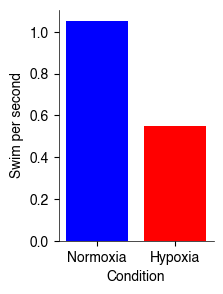

In [4]:
plt.figure(figsize=(2, 3))
# number of events per second for normoxia and hypoxia conditions
plt.bar([0, 1], [k_norm[0].shape[0]/10/60, k_hypo[0].shape[0]/10/60], color=['blue', 'red'])
plt.xlabel('Condition')
plt.xticks([0, 1], ['Normoxia', 'Hypoxia'])
plt.ylabel('Swim per second')
sns.despine()
plt.savefig('swim_freq.pdf')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


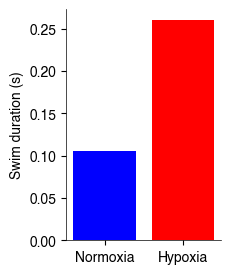

In [5]:
plt.figure(figsize=(2, 3))
plt.bar([0, 1], [k_norm[0].mean(), k_hypo[0].mean()], color=['blue', 'red'])
plt.ylabel('Swim duration (s)')
plt.xticks([0, 1], ['Normoxia', 'Hypoxia'])
sns.despine()
plt.savefig('swim_duration.pdf')